In [3]:
from google.colab import files

uploaded = files.upload()

Saving DATASET CNN NEW.zip to DATASET CNN NEW.zip


In [4]:
import zipfile

zip_file = list(uploaded.keys())[0]

with zipfile.ZipFile(zip_file, 'r') as zip_ref:
    zip_ref.extractall('/content/')

print("Dataset berhasil diekstrak!")

Dataset berhasil diekstrak!


In [5]:
import os

base = "/content/DATASET CNN NEW"

for kelas in os.listdir(base):
    folder = os.path.join(base, kelas)

    if os.path.isdir(folder):
        jumlah = len([
            f for f in os.listdir(folder)
            if f.lower().endswith((".jpg", ".jpeg", ".png"))
        ])

        print(f"{kelas}: {jumlah} gambar")

wood_waste: 50 gambar
metal_cans: 50 gambar
plastic_bottles: 50 gambar
paper_waste: 50 gambar


In [6]:
import os
import shutil
from sklearn.model_selection import train_test_split

# Lokasi dataset
base = "/content/DATASET CNN NEW"

# Folder hasil pembagian
output = "/content/dataset_split"

kelas = [
    "wood_waste",
    "paper_waste",
    "plastic_bottles",
    "metal_cans"
]

# Buat folder train, val, test
for split in ["train", "val", "test"]:
    for k in kelas:
        os.makedirs(os.path.join(output, split, k), exist_ok=True)

# Membagi data
for k in kelas:

    folder = os.path.join(base, k)

    images = [
        f for f in os.listdir(folder)
        if f.lower().endswith((".jpg", ".jpeg", ".png"))
    ]

    # 70% train, 30% sementara
    train_data, temp_data = train_test_split(
        images,
        test_size=0.30,
        random_state=42
    )

    # 15% validation, 15% test
    val_data, test_data = train_test_split(
        temp_data,
        test_size=0.50,
        random_state=42
    )

    # Copy gambar
    for f in train_data:
        shutil.copy2(
            os.path.join(folder, f),
            os.path.join(output, "train", k, f)
        )

    for f in val_data:
        shutil.copy2(
            os.path.join(folder, f),
            os.path.join(output, "val", k, f)
        )

    for f in test_data:
        shutil.copy2(
            os.path.join(folder, f),
            os.path.join(output, "test", k, f)
        )

    print(
        f"{k}: Train={len(train_data)}, "
        f"Val={len(val_data)}, Test={len(test_data)}"
    )

wood_waste: Train=35, Val=7, Test=8
paper_waste: Train=35, Val=7, Test=8
plastic_bottles: Train=35, Val=7, Test=8
metal_cans: Train=35, Val=7, Test=8


In [7]:
for split in ["train", "val", "test"]:
    print(f"\n{split.upper()}")

    for k in kelas:
        folder = os.path.join(output, split, k)

        jumlah = len([
            f for f in os.listdir(folder)
            if f.lower().endswith((".jpg", ".jpeg", ".png"))
        ])

        print(f"{k}: {jumlah}")


TRAIN
wood_waste: 35
paper_waste: 35
plastic_bottles: 35
metal_cans: 35

VAL
wood_waste: 7
paper_waste: 7
plastic_bottles: 7
metal_cans: 7

TEST
wood_waste: 8
paper_waste: 8
plastic_bottles: 8
metal_cans: 8


In [8]:
import tensorflow as tf

print(tf.config.list_physical_devices('GPU'))

[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [9]:
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator

IMG_SIZE = (224, 224)
BATCH_SIZE = 16

train_dir = "/content/dataset_split/train"
val_dir = "/content/dataset_split/val"
test_dir = "/content/dataset_split/test"

train_datagen = ImageDataGenerator(
    rescale=1./255
)

val_datagen = ImageDataGenerator(
    rescale=1./255
)

test_datagen = ImageDataGenerator(
    rescale=1./255
)

train_data = train_datagen.flow_from_directory(
    train_dir,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    shuffle=True,
    seed=42
)

val_data = val_datagen.flow_from_directory(
    val_dir,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    shuffle=False
)

test_data = test_datagen.flow_from_directory(
    test_dir,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    shuffle=False
)

print("Class:", train_data.class_indices)

Found 140 images belonging to 4 classes.
Found 28 images belonging to 4 classes.
Found 32 images belonging to 4 classes.
Class: {'metal_cans': 0, 'paper_waste': 1, 'plastic_bottles': 2, 'wood_waste': 3}


In [10]:
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras import layers, models

base_model = MobileNetV2(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

# Freeze model dasar
base_model.trainable = False

model_1 = models.Sequential([
    base_model,
    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.2),
    layers.Dense(4, activation="softmax")
])

model_1.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

model_1.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 4)              │         5,124 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,263,108 (8.63 MB)

 Trainable params: 5,124 (20.02 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [11]:
history_1 = model_1.fit(
    train_data,
    validation_data=val_data,
    epochs=10
)

Epoch 1/10
9/9 ━━━━━━━━━━━━━━━━━━━━ 43s 3s/step - accuracy: 0.3429 - loss: 1.5729 - val_accuracy: 0.3214 - val_loss: 1.1751
Epoch 2/10
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 52ms/step - accuracy: 0.7071 - loss: 0.7770 - val_accuracy: 0.6429 - val_loss: 0.7657
Epoch 3/10
9/9 ━━━━━━━━━━━━━━━━━━━━ 1s 57ms/step - accuracy: 0.8429 - loss: 0.4551 - val_accuracy: 0.7143 - val_loss: 0.5879
Epoch 4/10
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step - accuracy: 0.9143 - loss: 0.3322 - val_accuracy: 0.7857 - val_loss: 0.5070
Epoch 5/10
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step - accuracy: 0.9500 - loss: 0.2628 - val_accuracy: 0.8571 - val_loss: 0.4464
Epoch 6/10
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step - accuracy: 0.9571 - loss: 0.2039 - val_accuracy: 0.8214 - val_loss: 0.4060
Epoch 7/10
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step - accuracy: 0.9643 - loss: 0.1603 - val_accuracy: 0.8571 - val_loss: 0.3868
Epoch 8/10
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step - accuracy: 0.9714 - loss: 0.1637 - val_accuracy: 0.8929 - val_loss: 0.3716
E

In [12]:
from sklearn.metrics import classification_report, confusion_matrix
import numpy as np

# Prediksi data testing
pred_prob = model_1.predict(test_data)
pred_class = np.argmax(pred_prob, axis=1)

# Label sebenarnya
true_class = test_data.classes

# Nama kelas
class_names = list(test_data.class_indices.keys())

# Classification report
print("=== CLASSIFICATION REPORT ===")
print(
    classification_report(
        true_class,
        pred_class,
        target_names=class_names,
        digits=4
    )
)

2/2 ━━━━━━━━━━━━━━━━━━━━ 9s 35ms/step
=== CLASSIFICATION REPORT ===
                 precision    recall  f1-score   support

     metal_cans     0.7273    1.0000    0.8421         8
    paper_waste     0.7500    0.7500    0.7500         8
plastic_bottles     1.0000    0.6250    0.7692         8
     wood_waste     1.0000    1.0000    1.0000         8

       accuracy                         0.8438        32
      macro avg     0.8693    0.8438    0.8403        32
   weighted avg     0.8693    0.8438    0.8403        32



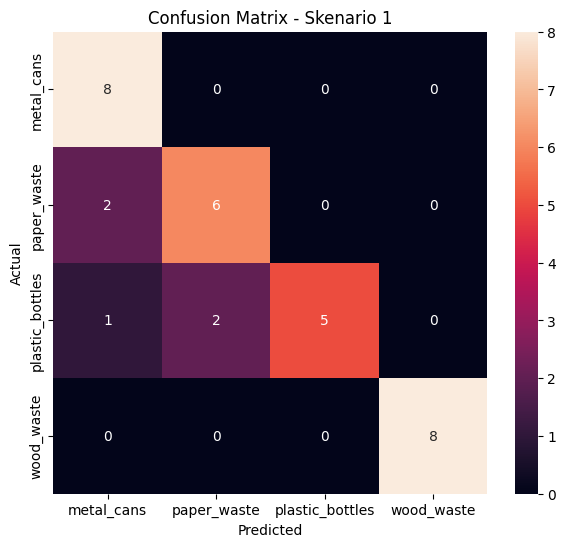

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns

cm = confusion_matrix(true_class, pred_class)

plt.figure(figsize=(7, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix - Skenario 1")
plt.show()

In [14]:
test_loss, test_accuracy = model_1.evaluate(test_data)

print("Test Accuracy:", test_accuracy)
print("Test Loss:", test_loss)

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 84ms/step - accuracy: 0.8438 - loss: 0.4265
Test Accuracy: 0.84375
Test Loss: 0.42653805017471313


## **Skenario 2: Data Augmentation**

In [15]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

train_datagen_2 = ImageDataGenerator(
    rescale=1./255,
    rotation_range=20,
    width_shift_range=0.15,
    height_shift_range=0.15,
    zoom_range=0.15,
    horizontal_flip=True
)

train_data_2 = train_datagen_2.flow_from_directory(
    train_dir,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    shuffle=True,
    seed=42
)

val_data_2 = val_datagen.flow_from_directory(
    val_dir,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    shuffle=False
)

test_data_2 = test_datagen.flow_from_directory(
    test_dir,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    shuffle=False
)

Found 140 images belonging to 4 classes.
Found 28 images belonging to 4 classes.
Found 32 images belonging to 4 classes.


In [16]:
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras import layers, models

base_model_2 = MobileNetV2(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

base_model_2.trainable = False

model_2 = models.Sequential([
    base_model_2,
    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.2),
    layers.Dense(4, activation="softmax")
])

model_2.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

In [17]:
history_2 = model_2.fit(
    train_data_2,
    validation_data=val_data_2,
    epochs=10
)

Epoch 1/10
9/9 ━━━━━━━━━━━━━━━━━━━━ 26s 2s/step - accuracy: 0.3714 - loss: 1.2487 - val_accuracy: 0.6071 - val_loss: 0.8716
Epoch 2/10
9/9 ━━━━━━━━━━━━━━━━━━━━ 2s 273ms/step - accuracy: 0.6286 - loss: 0.8483 - val_accuracy: 0.7857 - val_loss: 0.6780
Epoch 3/10
9/9 ━━━━━━━━━━━━━━━━━━━━ 2s 229ms/step - accuracy: 0.8000 - loss: 0.5647 - val_accuracy: 0.7857 - val_loss: 0.5324
Epoch 4/10
9/9 ━━━━━━━━━━━━━━━━━━━━ 2s 192ms/step - accuracy: 0.8500 - loss: 0.4095 - val_accuracy: 0.8929 - val_loss: 0.4710
Epoch 5/10
9/9 ━━━━━━━━━━━━━━━━━━━━ 2s 194ms/step - accuracy: 0.9071 - loss: 0.3179 - val_accuracy: 0.8929 - val_loss: 0.4829
Epoch 6/10
9/9 ━━━━━━━━━━━━━━━━━━━━ 2s 193ms/step - accuracy: 0.9429 - loss: 0.2825 - val_accuracy: 0.8929 - val_loss: 0.4202
Epoch 7/10
9/9 ━━━━━━━━━━━━━━━━━━━━ 2s 195ms/step - accuracy: 0.9500 - loss: 0.2339 - val_accuracy: 0.8929 - val_loss: 0.3805
Epoch 8/10
9/9 ━━━━━━━━━━━━━━━━━━━━ 2s 202ms/step - accuracy: 0.9357 - loss: 0.2466 - val_accuracy: 0.9286 - val_loss: 0

In [18]:
pred_prob_2 = model_2.predict(test_data_2)
pred_class_2 = np.argmax(pred_prob_2, axis=1)
true_class_2 = test_data_2.classes

print(classification_report(
    true_class_2,
    pred_class_2,
    target_names=class_names,
    digits=4
))

test_loss_2, test_accuracy_2 = model_2.evaluate(test_data_2)

print("Test Accuracy:", test_accuracy_2)
print("Test Loss:", test_loss_2)

2/2 ━━━━━━━━━━━━━━━━━━━━ 7s 36ms/step
                 precision    recall  f1-score   support

     metal_cans     0.7273    1.0000    0.8421         8
    paper_waste     0.8571    0.7500    0.8000         8
plastic_bottles     0.8333    0.6250    0.7143         8
     wood_waste     1.0000    1.0000    1.0000         8

       accuracy                         0.8438        32
      macro avg     0.8544    0.8438    0.8391        32
   weighted avg     0.8544    0.8438    0.8391        32

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step - accuracy: 0.8438 - loss: 0.3204
Test Accuracy: 0.84375
Test Loss: 0.32036900520324707


# **Skenario 3**

In [19]:
base_model_3 = MobileNetV2(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

base_model_3.trainable = False

model_3 = models.Sequential([
    base_model_3,
    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.4),
    layers.Dense(4, activation="softmax")
])

model_3.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

model_3.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_2      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 4)              │         5,124 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,263,108 (8.63 MB)

 Trainable params: 5,124 (20.02 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [20]:
history_3 = model_3.fit(
    train_data_2,
    validation_data=val_data_2,
    epochs=10
)

Epoch 1/10
9/9 ━━━━━━━━━━━━━━━━━━━━ 25s 2s/step - accuracy: 0.2643 - loss: 1.7097 - val_accuracy: 0.6429 - val_loss: 0.8924
Epoch 2/10
9/9 ━━━━━━━━━━━━━━━━━━━━ 2s 191ms/step - accuracy: 0.5643 - loss: 1.0200 - val_accuracy: 0.8214 - val_loss: 0.5979
Epoch 3/10
9/9 ━━━━━━━━━━━━━━━━━━━━ 3s 287ms/step - accuracy: 0.7071 - loss: 0.7010 - val_accuracy: 0.9286 - val_loss: 0.4460
Epoch 4/10
9/9 ━━━━━━━━━━━━━━━━━━━━ 2s 224ms/step - accuracy: 0.7786 - loss: 0.5198 - val_accuracy: 0.9286 - val_loss: 0.3709
Epoch 5/10
9/9 ━━━━━━━━━━━━━━━━━━━━ 2s 192ms/step - accuracy: 0.8357 - loss: 0.4243 - val_accuracy: 1.0000 - val_loss: 0.3265
Epoch 6/10
9/9 ━━━━━━━━━━━━━━━━━━━━ 2s 194ms/step - accuracy: 0.8643 - loss: 0.3828 - val_accuracy: 1.0000 - val_loss: 0.2908
Epoch 7/10
9/9 ━━━━━━━━━━━━━━━━━━━━ 2s 198ms/step - accuracy: 0.8357 - loss: 0.3679 - val_accuracy: 0.9643 - val_loss: 0.2720
Epoch 8/10
9/9 ━━━━━━━━━━━━━━━━━━━━ 2s 191ms/step - accuracy: 0.9000 - loss: 0.3309 - val_accuracy: 0.9643 - val_loss: 0

In [21]:
pred_prob_3 = model_3.predict(test_data_2)
pred_class_3 = np.argmax(pred_prob_3, axis=1)
true_class_3 = test_data_2.classes

print("=== SKENARIO 3 ===")

print(classification_report(
    true_class_3,
    pred_class_3,
    target_names=class_names,
    digits=4
))

test_loss_3, test_accuracy_3 = model_3.evaluate(test_data_2)

print("Test Accuracy:", test_accuracy_3)
print("Test Loss:", test_loss_3)

2/2 ━━━━━━━━━━━━━━━━━━━━ 7s 35ms/step
=== SKENARIO 3 ===
                 precision    recall  f1-score   support

     metal_cans     0.7273    1.0000    0.8421         8
    paper_waste     0.8750    0.8750    0.8750         8
plastic_bottles     1.0000    0.6250    0.7692         8
     wood_waste     1.0000    1.0000    1.0000         8

       accuracy                         0.8750        32
      macro avg     0.9006    0.8750    0.8716        32
   weighted avg     0.9006    0.8750    0.8716        32

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step - accuracy: 0.8750 - loss: 0.3311
Test Accuracy: 0.875
Test Loss: 0.3311445415019989


# **Skenario 4: Fine-Tuning MobileNetV2**

In [22]:
base_model_4 = MobileNetV2(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

base_model_4.trainable = True

for layer in base_model_4.layers[:-20]:
    layer.trainable = False

model_4 = models.Sequential([
    base_model_4,
    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.4),
    layers.Dense(4, activation="softmax")
])

model_4.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

model_4.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_3      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 4)              │         5,124 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,263,108 (8.63 MB)

 Trainable params: 1,211,204 (4.62 MB)

 Non-trainable params: 1,051,904 (4.01 MB)

In [23]:
history_4 = model_4.fit(
    train_data_2,
    validation_data=val_data_2,
    epochs=10
)

Epoch 1/10
9/9 ━━━━━━━━━━━━━━━━━━━━ 32s 2s/step - accuracy: 0.4714 - loss: 1.2591 - val_accuracy: 0.5000 - val_loss: 1.1041
Epoch 2/10
9/9 ━━━━━━━━━━━━━━━━━━━━ 2s 249ms/step - accuracy: 0.8000 - loss: 0.5521 - val_accuracy: 0.4286 - val_loss: 1.0106
Epoch 3/10
9/9 ━━━━━━━━━━━━━━━━━━━━ 2s 255ms/step - accuracy: 0.8786 - loss: 0.3771 - val_accuracy: 0.4643 - val_loss: 1.0404
Epoch 4/10
9/9 ━━━━━━━━━━━━━━━━━━━━ 2s 196ms/step - accuracy: 0.9357 - loss: 0.2439 - val_accuracy: 0.4643 - val_loss: 1.0997
Epoch 5/10
9/9 ━━━━━━━━━━━━━━━━━━━━ 2s 190ms/step - accuracy: 0.9357 - loss: 0.2181 - val_accuracy: 0.5000 - val_loss: 1.0304
Epoch 6/10
9/9 ━━━━━━━━━━━━━━━━━━━━ 2s 189ms/step - accuracy: 0.9786 - loss: 0.1227 - val_accuracy: 0.6071 - val_loss: 0.9107
Epoch 7/10
9/9 ━━━━━━━━━━━━━━━━━━━━ 2s 190ms/step - accuracy: 0.9500 - loss: 0.1660 - val_accuracy: 0.5714 - val_loss: 0.9505
Epoch 8/10
9/9 ━━━━━━━━━━━━━━━━━━━━ 2s 199ms/step - accuracy: 0.9857 - loss: 0.0873 - val_accuracy: 0.5714 - val_loss: 1

In [24]:
pred_prob_4 = model_4.predict(test_data_2)

pred_class_4 = np.argmax(pred_prob_4, axis=1)
true_class_4 = test_data_2.classes

print("=== SKENARIO 4 ===")

print(
    classification_report(
        true_class_4,
        pred_class_4,
        target_names=class_names,
        digits=4
    )
)

test_loss_4, test_accuracy_4 = model_4.evaluate(test_data_2)

print("Test Accuracy:", test_accuracy_4)
print("Test Loss:", test_loss_4)

2/2 ━━━━━━━━━━━━━━━━━━━━ 7s 40ms/step
=== SKENARIO 4 ===
                 precision    recall  f1-score   support

     metal_cans     0.7500    0.3750    0.5000         8
    paper_waste     1.0000    0.5000    0.6667         8
plastic_bottles     0.6154    1.0000    0.7619         8
     wood_waste     0.7273    1.0000    0.8421         8

       accuracy                         0.7188        32
      macro avg     0.7732    0.7188    0.6927        32
   weighted avg     0.7732    0.7188    0.6927        32

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step - accuracy: 0.7188 - loss: 0.9275
Test Accuracy: 0.71875
Test Loss: 0.9274815320968628


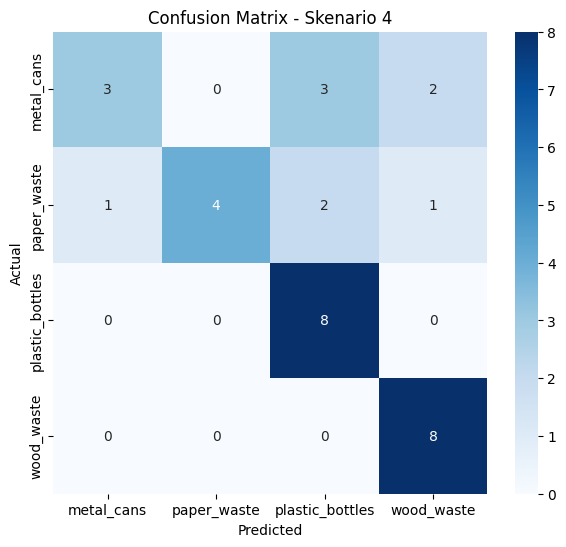

In [25]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

cm4 = confusion_matrix(true_class_4, pred_class_4)

plt.figure(figsize=(7, 6))
sns.heatmap(
    cm4,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix - Skenario 4")
plt.show()

In [26]:
hasil = {
    "Skenario": [
        "Skenario 1",
        "Skenario 2",
        "Skenario 3",
        "Skenario 4"
    ],
    "Perlakuan": [
        "Baseline",
        "Augmentation",
        "Augmentation + Dropout 0.4",
        "Fine-tuning MobileNetV2"
    ],
    "Accuracy": [
        0.8438,
        0.8438,
        0.8750,
        0.7188
    ],
    "Precision": [
        0.8693,
        0.8544,
        0.9006,
        0.7732
    ],
    "Recall": [
        0.8438,
        0.8438,
        0.8750,
        0.7188
    ],
    "F1-Score": [
        0.8403,
        0.8391,
        0.8716,
        0.6927
    ]
}

import pandas as pd

df_hasil = pd.DataFrame(hasil)

df_hasil

,Skenario,Perlakuan,Accuracy,Precision,Recall,F1-Score
0,Skenario 1,Baseline,0.8438,0.8693,0.8438,0.8403
1,Skenario 2,Augmentation,0.8438,0.8544,0.8438,0.8391
2,Skenario 3,Augmentation + Dropout 0.4,0.8750,0.9006,0.8750,0.8716
3,Skenario 4,Fine-tuning MobileNetV2,0.7188,0.7732,0.7188,0.6927


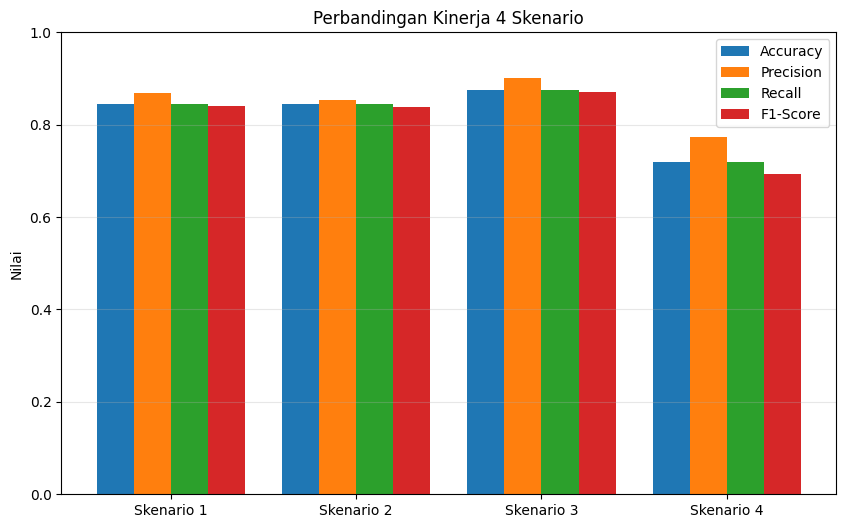

In [27]:
plt.figure(figsize=(10, 6))

x = np.arange(len(df_hasil))
width = 0.2

plt.bar(x - 1.5*width, df_hasil["Accuracy"], width, label="Accuracy")
plt.bar(x - 0.5*width, df_hasil["Precision"], width, label="Precision")
plt.bar(x + 0.5*width, df_hasil["Recall"], width, label="Recall")
plt.bar(x + 1.5*width, df_hasil["F1-Score"], width, label="F1-Score")

plt.xticks(x, df_hasil["Skenario"])
plt.ylabel("Nilai")
plt.ylim(0, 1)
plt.title("Perbandingan Kinerja 4 Skenario")
plt.legend()
plt.grid(axis="y", alpha=0.3)

plt.show()